[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/39Matheus/AED2/blob/Work_Branch/LOTUS.ipynb)

# L.O.T.U.S. — comparação de contextos lexicais em chinês e japonês

Aprendizes encontram caracteres iguais em palavras de línguas diferentes. **Quais caracteres
compartilhados apresentam contextos de coocorrência mais semelhantes ou diferentes nos
dicionários CC-CEDICT e JMdict? O resultado muda ao comparar o japonês com o chinês
tradicional ou simplificado?**

O público são estudantes interessados em explorar palavras associadas a esses caracteres.
A hipótese original sobre divergência semântica continua como motivação: esta análise
**mede estrutura ortográfica, não equivalência de significado nem falsos cognatos**.
As definições ficam disponíveis para inspeção qualitativa; confirmar divergência semântica
exigiria uma avaliação linguística adicional.

Execute as células na ordem: configuração → dados → limpeza/amostragem → redes → análise
→ visualizações → conclusão. Não é necessário usar todas as ferramentas do curso.

## 1. Modelagem e escolhas

- **Nós:** formas escritas de palavras, separadas por idioma/variante, e caracteres Han.
- **Aresta palavra–caractere:** a palavra contém aquele caractere. Grafo simples, não dirigido,
  sem peso; repetição do caractere na mesma palavra conta uma vez.
- **Partições:** palavras e caracteres. Palavras iguais em línguas distintas continuam sendo
  nós distintos; caracteres com o mesmo código Unicode se unem na composição das redes.
- **Projeção sobre caracteres:** dois caracteres se ligam se aparecem numa mesma palavra;
  o peso conta quantas formas escritas distintas os contêm. O Jaccard compara conjuntos de
  vizinhos dessa projeção entre línguas, no universo de caracteres compartilhados.
- **Simplificado × tradicional:** correspondência do CC-CEDICT é uma relação extra usada
  somente na visualização, em outro grafo. Ela não entra nas métricas bipartidas.
- **Fora do modelo:** frequência de uso, ordem e repetição dos caracteres, pronúncia como
  relação, equivalência semântica e equivalência entre grafias Han diferentes. NFC é aplicado;
  não há conversão automática simplificado/tradicional/japonês nem NFKC.

Conceitos: modelagem/grau (semana 2), componentes (semana 4), redes bipartidas, matriz de
incidência, projeção, coocorrência e Jaccard (semana 6).

## 2. Configuração

Localmente, instale `requirements.txt` antes de abrir o notebook. No Colab, a próxima célula
instala as mesmas versões. A fonte CJK é opcional para o cálculo; para rótulos legíveis em
Linux, instale `fonts-noto-cjk` (`apt-get install -y fonts-noto-cjk`) e reinicie o kernel.

`N_CN` limita **pares de grafias chinesas únicos**; `N_JP`, **formas japonesas únicas**.
`-1` usa todos os dados, com maior custo de memória/projeção. A semente fixa torna a amostra
repetível para os mesmos arquivos. Os limites visuais não afetam as métricas.

In [1]:
import sys
import subprocess

if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "networkx==3.4.2", "pandas==2.2.3", "matplotlib==3.10.0",
                           "requests==2.32.3", "pyvis==0.3.2"])

import gzip
import hashlib
import html as _html
import io
import json
import re
import unicodedata
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from IPython.display import HTML, display
from matplotlib.font_manager import FontProperties

N_CN = 1000
N_JP = 1000
SEED = 42
INTERACTIVE_INLINE = False  # True exibe os HTMLs também dentro do notebook.
DATA_DIR = Path("data/raw")
RESULTS_DIR = Path("resultados")
FIGURES_DIR = RESULTS_DIR / "figuras"
for folder in (DATA_DIR, RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

font_candidates = sorted(f for f in fm.findSystemFonts()
                         if "NotoSansCJK-Regular" in f or "NotoSerifCJK-Regular" in f)
cjk_font = FontProperties(fname=font_candidates[0]) if font_candidates else FontProperties()
if not font_candidates:
    print("Fonte CJK ausente: os cálculos funcionam, mas alguns rótulos podem não aparecer.")
plt.rcParams["figure.dpi"] = 110


def save_figure(fig, title):
    slug = unicodedata.normalize("NFKD", title).encode("ascii", "ignore").decode()
    slug = re.sub(r"[^a-z0-9]+", "_", slug.lower()).strip("_")
    fig.savefig(FIGURES_DIR / f"{slug}.png", dpi=150, bbox_inches="tight")

## 3. Obtenção dos dados reais

Fontes: [CC-CEDICT/MDBG](https://www.mdbg.net/chinese/dictionary?page=cedict), chinês–inglês,
e [JMdict/EDRDG](https://www.edrdg.org/jmdict/j_jmdict.html), japonês–inglês (`JMdict_e`).
São dicionários, não corpora de frequência. Créditos e licenças estão no README.

Os `.gz` ficam em cache em `data/raw/`. A requisição usa timeout, verificação TLS padrão e
checagem de HTTP/gzip. Para atualizar, remova os dois arquivos do cache. O manifesto registra
URL, SHA-256 e momento da primeira leitura desta cópia. Os arquivos remotos são atualizados:
mesma semente sem os mesmos arquivos não garante os mesmos resultados.

In [2]:
SOURCES = {
    "cedict_1_0_ts_utf-8_mdbg.txt.gz":
        "https://www.mdbg.net/chinese/export/cedict/cedict_1_0_ts_utf-8_mdbg.txt.gz",
    "JMdict_e.gz": "https://ftp.edrdg.org/pub/Nihongo/JMdict_e.gz",
}
manifest_path = DATA_DIR / "manifesto.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}


def load_dictionary(filename):
    path = DATA_DIR / filename
    if path.exists():
        compressed = path.read_bytes()
    else:
        response = requests.get(SOURCES[filename], timeout=(15, 120))
        response.raise_for_status()
        compressed = response.content
    content = gzip.decompress(compressed)  # valida também arquivos em cache
    digest = hashlib.sha256(compressed).hexdigest()
    if not path.exists():
        path.write_bytes(compressed)
    if manifest.get(filename, {}).get("sha256") != digest:
        manifest[filename] = {
            "url": SOURCES[filename], "sha256": digest, "bytes": len(compressed),
            "primeira_leitura_utc": datetime.now(timezone.utc).isoformat(),
        }
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    return content


cedict_bytes = load_dictionary("cedict_1_0_ts_utf-8_mdbg.txt.gz")
jmdict_bytes = load_dictionary("JMdict_e.gz")
display(pd.DataFrame(manifest).T[["bytes", "sha256"]])

,bytes,sha256
cedict_1_0_ts_utf-8_mdbg.txt.gz,3981631,2d42d41f75df8708d9d9b236d8ae15ecf1cef525aef8eb...
JMdict_e.gz,10586544,e84b7515b481485fe17f79939144bfbbd5456386768998...


## 4. Parsing e limpeza

CC-CEDICT: ignora comentários e reporta linhas não reconhecidas. JMdict: preserva **todas as
grafias `keb`**, não só a primeira; respeita restrições de grafia de leituras e sentidos.
As definições são inglesas e são reunidas por grafia; isso não alinha sentidos entre línguas.
Formas sem Han ficam fora. Homógrafos/sentidos repetidos se unem por forma escrita para
que uma entrada com várias definições não aumente o grau artificialmente.

In [3]:
def is_han(char):
    value = ord(char)
    return any(start <= value <= end for start, end in (
        (0x3400, 0x4DBF), (0x4E00, 0x9FFF), (0xF900, 0xFAFF),
        (0x20000, 0x2A6DF), (0x2A700, 0x2B73F), (0x2B740, 0x2B81F),
        (0x2B820, 0x2CEAF), (0x2CEB0, 0x2EBEF), (0x2EBF0, 0x2EE5F),
        (0x2F800, 0x2FA1F), (0x30000, 0x3134F), (0x31350, 0x323AF), (0x323B0, 0x3347F),
    ))


def extract_han(text):
    return sorted({char for char in text if is_han(char)})


def normalize(text):
    return unicodedata.normalize("NFC", text.strip())


def join_unique(values):
    return "; ".join(dict.fromkeys(value for value in values if value))


def parse_cedict(content):
    pattern = re.compile(r"^(\S+)\s+(\S+)\s+\[(.*?)\]\s+/(.*)/$")
    entries, rejected = [], 0
    for line in content.decode("utf-8").splitlines():
        if not line.strip() or line.startswith("#"):
            continue
        match = pattern.match(line)
        if match is None:
            rejected += 1
            continue
        traditional, simplified, pinyin, definition = match.groups()
        entries.append({"traditional": normalize(traditional),
                        "simplified": normalize(simplified),
                        "pinyin": pinyin, "definition": definition})
    return pd.DataFrame(entries, columns=["traditional", "simplified", "pinyin", "definition"]), rejected


def parse_jmdict(content):
    entries = []
    # Limpa cada entry após o processamento, evitando manter toda a árvore XML.
    context = ET.iterparse(io.BytesIO(content), events=("start", "end"))
    _, root = next(context)
    for event, entry in context:
        if event != "end" or entry.tag != "entry":
            continue
        for spelling in entry.findall("k_ele/keb"):
            word = spelling.text or ""
            readings = [r.findtext("reb", "") for r in entry.findall("r_ele")
                        if r.find("re_nokanji") is None
                        and (not r.findall("re_restr")
                             or word in [x.text for x in r.findall("re_restr")])]
            meanings = []
            for sense in entry.findall("sense"):
                restrictions = [x.text for x in sense.findall("stagk")]
                if restrictions and word not in restrictions:
                    continue
                reading_restrictions = [x.text for x in sense.findall("stagr")]
                if reading_restrictions and not set(readings).intersection(reading_restrictions):
                    continue
                for gloss in sense.findall("gloss"):
                    if gloss.get("{http://www.w3.org/XML/1998/namespace}lang", "eng") == "eng":
                        meanings.append(gloss.text or "")
            entries.append({"word": normalize(word), "reading": join_unique(readings),
                            "definition": join_unique(meanings)})
        root.clear()
    return pd.DataFrame(entries, columns=["word", "reading", "definition"])


df_cn_raw, rejected_cn = parse_cedict(cedict_bytes)
df_jp_raw = parse_jmdict(jmdict_bytes)
del cedict_bytes, jmdict_bytes

cn_valid = df_cn_raw[
    df_cn_raw["simplified"].map(lambda w: bool(extract_han(w)))
    & df_cn_raw["traditional"].map(lambda w: bool(extract_han(w)))
]
jp_valid = df_jp_raw[df_jp_raw["word"].map(lambda w: bool(extract_han(w)))]
df_cn = cn_valid.groupby(["simplified", "traditional"], as_index=False, sort=True).agg(
    pinyin=("pinyin", join_unique), definition=("definition", join_unique))
df_jp = jp_valid.groupby("word", as_index=False, sort=True).agg(
    reading=("reading", join_unique), definition=("definition", join_unique))

df_cleaning = pd.DataFrame([
    {"fonte": "CC-CEDICT", "registros_lidos": len(df_cn_raw),
     "sem_han": len(df_cn_raw) - len(cn_valid),
     "registros_agrupados": len(cn_valid) - len(df_cn), "unidades_limpas": len(df_cn)},
    {"fonte": "JMdict (grafias)", "registros_lidos": len(df_jp_raw),
     "sem_han": len(df_jp_raw) - len(jp_valid),
     "registros_agrupados": len(jp_valid) - len(df_jp), "unidades_limpas": len(df_jp)},
])
print(f"Linhas CC-CEDICT não reconhecidas: {rejected_cn}")
if df_cn.empty or df_jp.empty:
    raise ValueError("Uma fonte não produziu formas com Han; confira download e parsing.")
display(df_cleaning)
df_cleaning.to_csv(RESULTS_DIR / "limpeza.csv", index=False)

Linhas CC-CEDICT não reconhecidas: 0


,fonte,registros_lidos,sem_han,registros_agrupados,unidades_limpas
0,CC-CEDICT,125301,59,2489,122753
1,JMdict (grafias),233659,2162,4421,227076


## 5. Amostra reproduzível

Amostragem aleatória sem reposição depois da limpeza, com ordenação estável e semente fixa,
em vez de `head(1000)`, que herda a ordenação editorial dos dicionários. As amostras dos
dois idiomas são independentes. Não representam uso cotidiano ou contextos completos;
graus baixos e Jaccard baixo podem refletir poucos dados, não uma diferença linguística.

In [4]:
def sample_rows(df, limit):
    if not isinstance(limit, int) or (limit != -1 and limit < 1):
        raise ValueError("O limite deve ser -1 (tudo) ou um inteiro positivo.")
    return (df.copy() if limit == -1 or limit >= len(df)
            else df.sample(n=limit, random_state=SEED)).reset_index(drop=True)


df_cn_sample = sample_rows(df_cn, N_CN)
df_jp_sample = sample_rows(df_jp, N_JP)
print(f"Amostra: {len(df_cn_sample)} pares chineses; {len(df_jp_sample)} formas japonesas.")
df_cn_sample.to_csv(RESULTS_DIR / "amostra_cn.csv", index=False)
df_jp_sample.to_csv(RESULTS_DIR / "amostra_jp.csv", index=False)

Amostra: 1000 pares chineses; 1000 formas japonesas.


## 6. Construção das redes bipartidas

Uma única função cobre os três conjuntos. O prefixo identifica o idioma/variante da palavra.
O grau de um caractere conta **formas escritas distintas no dicionário amostrado**, não uso.
Os testes de integridade conferem as partições e a ausência de arestas palavra–palavra.

In [5]:
def build_word_character_graph(df, column, prefix, language, reading_column):
    graph = nx.Graph(language=language)
    words = df.groupby(column, sort=True).agg(
        definition=("definition", join_unique), reading=(reading_column, join_unique))
    for word, row in words.iterrows():
        chars = extract_han(word)
        if not chars:
            continue
        node = prefix + word
        graph.add_node(node, bipartite="word", language=language, label=word,
                       definition=row["definition"], reading=row["reading"])
        for char in chars:
            char_node = "CHAR:" + char
            graph.add_node(char_node, bipartite="character", language="shared", label=char)
            graph.add_edge(node, char_node, relation="contains_character")
    return graph


G_cn_trad = build_word_character_graph(df_cn_sample, "traditional", "CN_TRAD_WORD:",
                                     "chinese_traditional", "pinyin")
G_cn_simp = build_word_character_graph(df_cn_sample, "simplified", "CN_WORD:",
                                     "chinese_simplified", "pinyin")
G_jp = build_word_character_graph(df_jp_sample, "word", "JP_WORD:", "japanese", "reading")
GRAPHS = {"cn_tradicional": G_cn_trad, "cn_simplificado": G_cn_simp, "japones": G_jp}


def partition(graph, kind):
    return sorted(n for n, data in graph.nodes(data=True) if data["bipartite"] == kind)


for name, graph in GRAPHS.items():
    assert nx.is_bipartite(graph), name
    assert nx.number_of_selfloops(graph) == 0, name
    assert all(graph.nodes[u]["bipartite"] != graph.nodes[v]["bipartite"]
               for u, v in graph.edges), name

G_jp_vs_trad = nx.compose(G_jp, G_cn_trad)
G_jp_vs_simp = nx.compose(G_jp, G_cn_simp)

## 7. Estrutura, componentes e grau normalizado

A densidade bipartida é `arestas / (palavras × caracteres)`, considerando apenas ligações
permitidas entre partições. A maior componente indica a parte conectada da rede; não mede
semelhança semântica. O grau normalizado divide pelo total de palavras de cada rede,
facilitando a comparação entre tamanhos diferentes, sem corrigir diferenças de cobertura.

In [6]:
summary = []
for name, graph in GRAPHS.items():
    n_words = len(partition(graph, "word"))
    n_chars = len(partition(graph, "character"))
    components = sorted((len(c) for c in nx.connected_components(graph)), reverse=True)
    summary.append({"rede": name, "palavras": n_words, "caracteres": n_chars,
                    "arestas": graph.number_of_edges(), "componentes": len(components),
                    "maior_componente_pct": 100 * components[0] / len(graph),
                    "densidade_bipartida": graph.number_of_edges() / (n_words * n_chars)})
df_summary = pd.DataFrame(summary)
display(df_summary.round(4))
df_summary.to_csv(RESULTS_DIR / "resumo_redes.csv", index=False)

,rede,palavras,caracteres,arestas,componentes,maior_componente_pct,densidade_bipartida
0,cn_tradicional,1000,1398,2572,209,75.7298,0.0018
1,cn_simplificado,1000,1391,2572,205,76.0351,0.0018
2,japones,1000,1127,2564,113,84.4382,0.0023


## 8. Matriz de incidência — exemplo legível

Linha = palavra, coluna = caractere; 1 indica presença. A tabela usa só oito palavras para
inspeção. As métricas seguintes usam as redes inteiras da amostra, não esta miniatura.

In [7]:
def incidence_example(graph, max_words=8):
    words = partition(graph, "word")[:max_words]
    chars = sorted({char for word in words for char in graph.neighbors(word)})
    return pd.DataFrame(
        [[int(graph.has_edge(word, char)) for char in chars] for word in words],
        index=[graph.nodes[word]["label"] for word in words],
        columns=[graph.nodes[char]["label"] for char in chars],
    ).rename_axis("palavra")


for name, graph in GRAPHS.items():
    print(name)
    display(incidence_example(graph))

cn_tradicional


,䇲,一,三,二,個,兒,化,坑,小,心,...,木,板,無,用,眼,胎,蔔,蘿,陣,難
palavra,,,,,,,,,,,,,,,,,,,,,
䇲,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
一個蘿蔔一個坑,0,1,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,1,1,0,0
一小陣兒,0,1,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
一心二用,0,1,0,1,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
一木難支,0,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
一板三眼,0,1,1,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
一無所有,0,1,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
一胎化,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0


cn_simplificado


,䇲,一,三,个,举,二,儿,动,卜,坑,...,支,无,有,木,板,用,眼,萝,阵,难
palavra,,,,,,,,,,,,,,,,,,,,,
䇲,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
一个萝卜一个坑,0,1,0,1,0,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,0
一举一动,0,1,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
一小阵儿,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
一心二用,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
一无所有,0,1,0,0,0,0,0,0,0,0,...,0,1,1,0,0,0,0,0,0,0
一木难支,0,1,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,1
一板三眼,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0


japones


,仏,向,味,噌,夜,学,月,校,様,煮,行,護,養
palavra,,,,,,,,,,,,,
あが仏,1,0,0,0,0,0,0,0,0,0,0,0,0
あね様,0,0,0,0,0,0,0,0,1,0,0,0,0
あわせ味噌,0,0,1,1,0,0,0,0,0,0,0,0,0
いため煮,0,0,0,0,0,0,0,0,0,1,0,0,0
いわき養護学校,0,0,0,0,0,1,0,1,0,0,0,1,1
うわてを行く,0,0,0,0,0,0,0,0,0,0,1,0,0
おぼろ月夜,0,0,0,0,1,0,1,0,0,0,0,0,0
お向い,0,1,0,0,0,0,0,0,0,0,0,0,0


## 9. Projeção e comparação dos contextos

A projeção liga caracteres que aparecem juntos em palavras. O peso conta palavras distintas
em comum, mas a comparação abaixo usa **presença/ausência dos vizinhos**, sem pesos.

Para cada comparação, restringimos os contextos ao mesmo universo de caracteres presentes
nas duas línguas. Para um caractere `c`, `J(c) = |V_CN(c) ∩ V_JP(c)| / |V_CN(c) ∪ V_JP(c)|`.
Se ambos os conjuntos são vazios, o resultado é indefinido (`NaN`), não similaridade perfeita.
Também mostramos o suporte (graus) e o tamanho dos contextos. As duas comparações podem ter
universos diferentes; suas médias não são um teste de efeito causal da variante escrita.

Triângulos/clustering da projeção podem surgir só porque uma palavra tem três caracteres.
Por isso, não os interpretamos como evidência de comunidade semântica.

In [8]:
PROJECTIONS = {
    name: nx.algorithms.bipartite.weighted_projected_graph(graph, partition(graph, "character"))
    for name, graph in GRAPHS.items()
}


def compare_contexts(cn_graph, jp_graph, cn_projection, jp_projection):
    shared = set(partition(cn_graph, "character")) & set(partition(jp_graph, "character"))
    n_cn = len(partition(cn_graph, "word"))
    n_jp = len(partition(jp_graph, "word"))
    columns = ["caractere", "grau_cn", "grau_jp", "grau_rel_cn", "grau_rel_jp",
               "contexto_cn", "contexto_jp", "intersecao", "uniao", "jaccard"]
    rows = []
    for char in sorted(shared):
        cn_neighbors = set(cn_projection.neighbors(char)) & shared
        jp_neighbors = set(jp_projection.neighbors(char)) & shared
        union = cn_neighbors | jp_neighbors
        intersection = cn_neighbors & jp_neighbors
        rows.append([char.removeprefix("CHAR:"), cn_graph.degree(char), jp_graph.degree(char),
                     cn_graph.degree(char) / n_cn, jp_graph.degree(char) / n_jp,
                     len(cn_neighbors), len(jp_neighbors), len(intersection), len(union),
                     len(intersection) / len(union) if union else float("nan")])
    return pd.DataFrame(rows, columns=columns)


COMPARISONS = {}
for variant in ("cn_tradicional", "cn_simplificado"):
    table = compare_contexts(GRAPHS[variant], G_jp, PROJECTIONS[variant], PROJECTIONS["japones"])
    COMPARISONS[variant] = table
    table.to_csv(RESULTS_DIR / f"contextos_{variant}.csv", index=False)
    print(f"{variant} × japonês: {len(table)} caracteres compartilhados; "
          f"{table['jaccard'].notna().sum()} com Jaccard definido.")
    display(table.sort_values(["grau_cn", "caractere"], ascending=[False, True]).head(12).round(4))

cn_tradicional × japonês: 533 caracteres compartilhados; 519 com Jaccard definido.


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
18,人,16,11,0.016,0.011,26,23,3,46,0.0652
110,地,15,14,0.015,0.014,20,22,2,40,0.0500
133,子,14,12,0.014,0.012,9,20,1,28,0.0357
123,大,13,21,0.013,0.021,21,26,3,44,0.0682
0,一,12,13,0.012,0.013,21,12,1,32,0.0312
155,山,12,6,0.012,0.006,11,11,0,22,0.0000
5,不,11,5,0.011,0.005,15,5,1,19,0.0526
300,無,11,6,0.011,0.006,18,8,0,26,0.0000
513,頭,11,5,0.011,0.005,10,4,0,14,0.0000
4,下,10,6,0.010,0.006,12,8,0,20,0.0000


cn_simplificado × japonês: 429 caracteres compartilhados; 417 com Jaccard definido.


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
18,人,16,11,0.016,0.011,22,16,3,35,0.0857
107,地,15,14,0.015,0.014,17,17,1,33,0.0303
128,子,14,12,0.014,0.012,9,17,1,25,0.0400
118,大,13,21,0.013,0.021,18,24,4,38,0.1053
0,一,12,13,0.012,0.013,16,10,1,25,0.0400
150,山,12,6,0.012,0.006,11,9,0,20,0.0000
5,不,11,5,0.011,0.005,16,5,1,20,0.0500
4,下,10,6,0.010,0.006,12,7,0,19,0.0000
56,分,10,13,0.010,0.013,8,16,4,20,0.2000
177,心,10,5,0.010,0.005,16,4,2,18,0.1111


### Contextos com maior e menor sobreposição

O filtro de suporte (`MIN_SUPPORT = 3`) evita destacar caracteres presentes em apenas uma
ou duas palavras de um dos idiomas. É uma regra exploratória, não validação estatística.
Se o filtro não produzir resultados, aumente a amostra; não há motivo para forçar um ranking.
As tabelas exportadas conservam todos os caracteres, inclusive os excluídos do ranking.

cn_tradicional: 117 caracteres com suporte ≥ 3 nos dois idiomas.
Menor sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
2,三,3,8,0.003,0.008,7,11,0,18,0.0
4,下,10,6,0.010,0.006,12,8,0,20,0.0
14,二,3,10,0.003,0.010,5,12,0,17,0.0
42,先,3,6,0.003,0.006,10,6,0,16,0.0
43,光,4,5,0.004,0.005,4,9,0,13,0.0


Maior sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
524,骨,4,3,0.004,0.003,7,3,2,8,0.2500
430,解,5,4,0.005,0.004,11,5,3,13,0.2308
223,新,6,4,0.006,0.004,4,7,2,9,0.2222
218,放,3,6,0.003,0.006,7,5,2,10,0.2000
375,線,5,5,0.005,0.005,10,8,3,15,0.2000


cn_simplificado: 99 caracteres com suporte ≥ 3 nos dois idiomas.
Menor sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
2,三,3,8,0.003,0.008,5,10,0,15,0.0
4,下,10,6,0.010,0.006,12,7,0,19,0.0
8,主,3,3,0.003,0.003,1,6,0,7,0.0
13,事,3,13,0.003,0.013,3,13,0,16,0.0
14,二,3,10,0.003,0.010,5,12,0,17,0.0


Maior sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
424,骨,4,3,0.004,0.003,5,3,2,6,0.3333
385,解,5,4,0.005,0.004,8,3,2,9,0.2222
56,分,10,13,0.010,0.013,8,16,4,20,0.2000
340,管,5,5,0.005,0.005,2,4,1,5,0.2000
297,理,8,11,0.008,0.011,11,11,3,19,0.1579


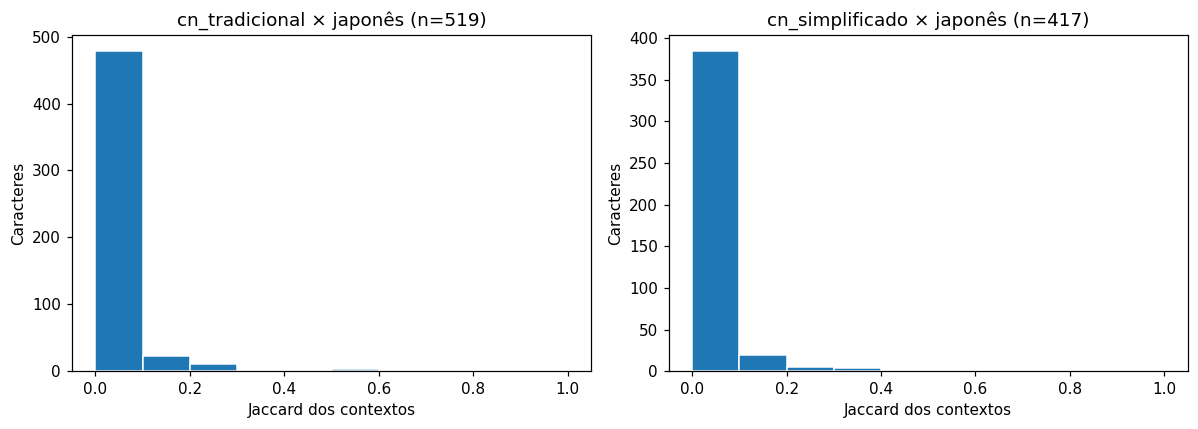

In [9]:
MIN_SUPPORT = 3
for variant, table in COMPARISONS.items():
    eligible = table[(table["grau_cn"] >= MIN_SUPPORT) & (table["grau_jp"] >= MIN_SUPPORT)]
    eligible = eligible.dropna(subset=["jaccard"])
    print(f"{variant}: {len(eligible)} caracteres com suporte ≥ {MIN_SUPPORT} nos dois idiomas.")
    if eligible.empty:
        print("Sem ranking com esse suporte na amostra atual.")
        continue
    print("Menor sobreposição ortográfica:")
    display(eligible.sort_values(["jaccard", "caractere"]).head(5).round(4))
    print("Maior sobreposição ortográfica:")
    display(eligible.sort_values(["jaccard", "caractere"], ascending=[False, True]).head(5).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (variant, table) in zip(axes, COMPARISONS.items()):
    values = table["jaccard"].dropna()
    ax.hist(values, bins=[i / 10 for i in range(11)], edgecolor="white")
    ax.set(title=f"{variant} × japonês (n={len(values)})", xlabel="Jaccard dos contextos", ylabel="Caracteres")
fig.tight_layout()
save_figure(fig, "jaccard_contextos")
plt.show()

## 10. Inspeção de palavras e definições

Troque `CHAR_TO_INSPECT` para investigar os rankings. A tabela mostra exemplos lexicais
reais; as traduções e os sentidos foram agrupados por grafia e não devem ser tratados como
pares de tradução. Nenhum limiar de Jaccard identifica automaticamente um falso cognato.

In [10]:
table = COMPARISONS["cn_tradicional"].dropna(subset=["jaccard"])
CHAR_TO_INSPECT = table.sort_values(["jaccard", "caractere"]).iloc[0]["caractere"] if not table.empty else None


def inspect_character(char, limit=5):
    rows = []
    for name, graph in GRAPHS.items():
        node = "CHAR:" + char
        if node not in graph:
            continue
        for word in sorted(graph.neighbors(node))[:limit]:
            data = graph.nodes[word]
            rows.append({"rede": name, "palavra": data["label"],
                         "leitura": data["reading"], "definicao": data["definition"]})
    return pd.DataFrame(rows, columns=["rede", "palavra", "leitura", "definicao"])


if CHAR_TO_INSPECT:
    print("Caractere inspecionado:", CHAR_TO_INSPECT)
    display(inspect_character(CHAR_TO_INSPECT))
else:
    print("Sem caractere com contexto comparável nesta amostra.")

Caractere inspecionado: 三


,rede,palavra,leitura,definicao
0,cn_tradicional,一板三眼,yi1 ban3 san1 yan3,lit. one strong beat and three weak beats in a...
1,cn_tradicional,下三爛,xia4 san1 lan4,variant of 下三濫|下三滥[xia4 san1 lan4]
2,cn_tradicional,傳三過四,chuan2 san1 guo4 si4,to spread rumors/to gossip
3,cn_simplificado,一板三眼,yi1 ban3 san1 yan3,lit. one strong beat and three weak beats in a...
4,cn_simplificado,下三烂,xia4 san1 lan4,variant of 下三濫|下三滥[xia4 san1 lan4]
5,cn_simplificado,传三过四,chuan2 san1 guo4 si4,to spread rumors/to gossip
6,japones,三々九度,さんさんくど,three-times-three exchange of nuptial cups
7,japones,三の糸,さんのいと,"third string (of a shamisen, etc.)"
8,japones,三代実録,さんだいじつろく,Sandai Jitsuroku (sixth of the six classical J...
9,japones,三大節,さんだいせつ,the three grand national holidays (Prayer to t...


## 11. Visualizações comparativas

Mantemos as visualizações do projeto, com amostras menores para leitura. Os caracteres são
escolhidos por presença nos dois lados; isto favorece hubs e **não é amostra para inferência**.
As figuras são salvas em `resultados/figuras/`. Pares simplificado/tradicional vêm da mesma
entrada do CC-CEDICT, não de uma inferência automática por similaridade.

In [11]:
# Visualizações comparativas com idiomas identificados, cores e layout em colunas.
# A seleção usa os caracteres com maior presença nos DOIS idiomas, em vez dos primeiros
# caracteres em ordem Unicode. A rede completa continua disponível nas variáveis G_*.

COMPARE_CHARS = 8          # quantidade de caracteres compartilhados exibidos
WORDS_PER_CHAR_COMPARE = 2  # quantidade máxima de palavras por caractere e idioma
PAIRS_TO_SHOW = 12          # pares distintos na comparação simplificado/tradicional

COLOR_LEFT = "#9EC9FF"      # palavras do idioma/variante à esquerda
COLOR_CHAR = "#B8E0D2"      # caracteres compartilhados
COLOR_RIGHT = "#FFCC99"     # palavras do idioma/variante à direita
EDGE_LEFT = "#6495C8"
EDGE_RIGHT = "#D18A4B"


def _word_neighbors(graph, char_node, prefixes):
    """Vizinhos de um caractere que são palavras de um ou mais idiomas."""
    return [n for n in graph.neighbors(char_node) if n.startswith(prefixes)]


def _display_node_label(node, prefixes):
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    for prefix in prefixes:
        if node.startswith(prefix):
            return node[len(prefix):]
    return node


def plot_language_comparison(graph, title, left_name, left_prefixes,
                             right_name, right_prefixes,
                             max_chars=COMPARE_CHARS,
                             words_per_char=WORDS_PER_CHAR_COMPARE):
    """Grafo em três colunas: palavras à esquerda, caracteres no centro, palavras à direita."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)

    ranked_chars = []
    for node, data in graph.nodes(data=True):
        if data.get("bipartite") != "character":
            continue
        left_words = _word_neighbors(graph, node, left_prefixes)
        right_words = _word_neighbors(graph, node, right_prefixes)
        # Só comparar caracteres que realmente aparecem nos dois lados.
        if left_words and right_words:
            ranked_chars.append((node, left_words, right_words))

    ranked_chars.sort(
        key=lambda item: (
            min(len(item[1]), len(item[2])),
            len(item[1]) + len(item[2]),
            item[0]
        ),
        reverse=True
    )
    chosen = ranked_chars[:max_chars]
    if not chosen:
        print(f"Não foram encontrados caracteres compartilhados para: {title}")
        return

    # Coordenadas previsíveis em colunas, para que cada cor e idioma fique evidente.
    spacing = 1.35
    center_y = (len(chosen) - 1) * spacing / 2
    pos = {}
    chosen_nodes = set()
    left_y_suggestions = {}
    right_y_suggestions = {}
    char_nodes = []

    for idx, (char_node, left_words, right_words) in enumerate(chosen):
        y = center_y - idx * spacing
        pos[char_node] = (0.0, y)
        chosen_nodes.add(char_node)
        char_nodes.append(char_node)

        # Seleciona palavras com mais ligações primeiro; isso tende a mostrar palavras
        # que ilustram melhor o uso dos caracteres e reduz a chance de grupos vazios.
        left_words = sorted(left_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]
        right_words = sorted(right_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]

        for words, suggestions in ((left_words, left_y_suggestions), (right_words, right_y_suggestions)):
            if len(words) == 1:
                offsets = [0.0]
            else:
                offsets = [((j / (len(words) - 1)) - 0.5) * 0.78 for j in range(len(words))]
            for word_node, offset in zip(words, offsets):
                chosen_nodes.add(word_node)
                suggestions.setdefault(word_node, []).append(y + offset)

    # Mantém a ordem sugerida, com espaçamento uniforme para evitar rótulos sobrepostos.
    for x, suggestions in ((-3.7, left_y_suggestions), (3.7, right_y_suggestions)):
        ordered = sorted(suggestions, key=lambda n: (-sum(suggestions[n]) / len(suggestions[n]), n))
        for i, node in enumerate(ordered):
            y = 0 if len(ordered) == 1 else center_y + 0.4 - i * (2 * center_y + 0.8) / (len(ordered) - 1)
            pos[node] = (x, y)

    sample = graph.subgraph(chosen_nodes).copy()
    left_nodes = [n for n in sample.nodes if n.startswith(left_prefixes)]
    right_nodes = [n for n in sample.nodes if n.startswith(right_prefixes)]
    center_nodes = [n for n in sample.nodes if n.startswith("CHAR:")]
    left_edges, right_edges = [], []
    for u, v in sample.edges():
        if u.startswith(left_prefixes) or v.startswith(left_prefixes):
            left_edges.append((u, v))
        elif u.startswith(right_prefixes) or v.startswith(right_prefixes):
            right_edges.append((u, v))

    fig_height = max(9.5, len(chosen) * 0.68)
    fig, ax = plt.subplots(figsize=(17, fig_height))
    nx.draw_networkx_edges(sample, pos, edgelist=left_edges, edge_color=EDGE_LEFT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_edges(sample, pos, edgelist=right_edges, edge_color=EDGE_RIGHT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=left_nodes, node_color=COLOR_LEFT,
                           node_size=520, edgecolors="#35516E", linewidths=0.7, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=center_nodes, node_color=COLOR_CHAR,
                           node_size=1050, edgecolors="#386B59", linewidths=1.2, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=right_nodes, node_color=COLOR_RIGHT,
                           node_size=520, edgecolors="#88572B", linewidths=0.7, ax=ax)

    # Rótulos manuais para usar a fonte CJK também nos nós e manter a leitura nítida.
    for node, (x, y) in pos.items():
        label = _display_node_label(node, left_prefixes + right_prefixes)
        fontsize = 13 if node.startswith("CHAR:") else 8.5
        if node.startswith("CHAR:"):
            label_color = COLOR_CHAR
        elif node.startswith(left_prefixes):
            label_color = COLOR_LEFT
        else:
            label_color = COLOR_RIGHT
        ax.text(x, y, label, fontproperties=cjk_font, fontsize=fontsize,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.94, pad=1.0),
                zorder=5)

    top_y = center_y + 1.25
    ax.text(-3.7, top_y, left_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)
    ax.text(0, top_y, "CARACTERES COMPARTILHADOS", ha="center", va="bottom",
            fontsize=12, fontweight="bold")
    ax.text(3.7, top_y, right_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)

    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0], [0], marker="o", color="w", label=left_name,
               markerfacecolor=COLOR_LEFT, markeredgecolor="#35516E", markersize=10),
        Line2D([0], [0], marker="o", color="w", label="Caractere Han/Kanji",
               markerfacecolor=COLOR_CHAR, markeredgecolor="#386B59", markersize=10),
        Line2D([0], [0], marker="o", color="w", label=right_name,
               markerfacecolor=COLOR_RIGHT, markeredgecolor="#88572B", markersize=10),
    ]
    ax.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.5, -0.035),
              ncol=3, frameon=False, fontsize=9)
    ax.set_title(title, fontsize=16, pad=22, fontweight="bold")
    ax.set_xlim(-5.7, 5.7)
    ax.set_ylim(-center_y - 1.3, top_y + 0.7)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, title)
    plt.show()
    print(f"{title}: {len(chosen)} caracteres compartilhados; "
          f"{len(left_nodes)} palavras à esquerda; {len(right_nodes)} palavras à direita; "
          f"{sample.number_of_edges()} ligações na amostra visual.")


def plot_simplified_traditional_pairs(df, max_pairs=PAIRS_TO_SHOW):
    """Mostra pares reais do CC-CEDICT em duas colunas alinhadas por entrada do dicionário."""
    pairs = df[["simplified", "traditional"]].copy()
    pairs = pairs.dropna()
    pairs["simplified"] = pairs["simplified"].astype(str).str.strip()
    pairs["traditional"] = pairs["traditional"].astype(str).str.strip()
    pairs = pairs[(pairs["simplified"] != "") & (pairs["traditional"] != "")]
    pairs = pairs[pairs["simplified"] != pairs["traditional"]]
    pairs = pairs.drop_duplicates(subset=["simplified", "traditional"]).reset_index(drop=True)

    if pairs.empty:
        print("Nenhum par diferente entre chinês simplificado e tradicional foi encontrado.")
        return

    # Amostra distribuída pelo dicionário em vez de usar apenas as primeiras entradas.
    n = min(max_pairs, len(pairs))
    if n == 1:
        selected_indices = [0]
    else:
        selected_indices = [round(i * (len(pairs) - 1) / (n - 1)) for i in range(n)]
    pairs = pairs.iloc[selected_indices].reset_index(drop=True)

    pair_graph = nx.Graph()
    pos = {}
    labels = {}
    for i, row in pairs.iterrows():
        simp_node = f"SIMP_PAIR_{i}"
        trad_node = f"TRAD_PAIR_{i}"
        y = (len(pairs) - 1) / 2 - i
        pair_graph.add_node(simp_node, language="chinese_simplified")
        pair_graph.add_node(trad_node, language="chinese_traditional")
        pair_graph.add_edge(simp_node, trad_node, relation="same_dictionary_entry")
        pos[simp_node] = (-1.9, y)
        pos[trad_node] = (1.9, y)
        labels[simp_node] = row["simplified"]
        labels[trad_node] = row["traditional"]

    fig, ax = plt.subplots(figsize=(14, max(9, len(pairs) * 0.47)))
    nx.draw_networkx_edges(pair_graph, pos, edge_color="#8B8B8B", alpha=0.68,
                           width=1.2, ax=ax)
    simp_nodes = [n for n in pair_graph.nodes if n.startswith("SIMP_PAIR_")]
    trad_nodes = [n for n in pair_graph.nodes if n.startswith("TRAD_PAIR_")]
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=simp_nodes, node_color=COLOR_LEFT,
                           node_size=850, edgecolors="#35516E", linewidths=0.8, ax=ax)
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=trad_nodes, node_color=COLOR_RIGHT,
                           node_size=850, edgecolors="#88572B", linewidths=0.8, ax=ax)
    for node, (x, y) in pos.items():
        label_color = COLOR_LEFT if node.startswith("SIMP_PAIR_") else COLOR_RIGHT
        ax.text(x, y, labels[node], fontproperties=cjk_font, fontsize=10,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.95, pad=1.0),
                zorder=5)
    top_y = (len(pairs) - 1) / 2 + 0.9
    ax.text(-1.9, top_y, "简体中文 — CHINÊS SIMPLIFICADO", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.text(1.9, top_y, "繁體中文 — CHINÊS TRADICIONAL", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.set_title("Comparação de formas correspondentes no CC-CEDICT", fontsize=15,
                 pad=20, fontweight="bold")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-0.9, top_y + 0.8)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, "pares_simplificado_tradicional")
    plt.show()
    print(f"Chinês simplificado × tradicional: {len(pairs)} pares distintos exibidos "
          f"(cada linha conecta duas formas da mesma entrada do CC-CEDICT).")

Resumo das redes completas carregadas:
  Caracteres no japonês: 1127
  Caracteres no chinês tradicional: 1398
  Caracteres no chinês simplificado: 1391
  Compartilhados japonês/tradicional: 533
  Compartilhados japonês/simplificado: 429


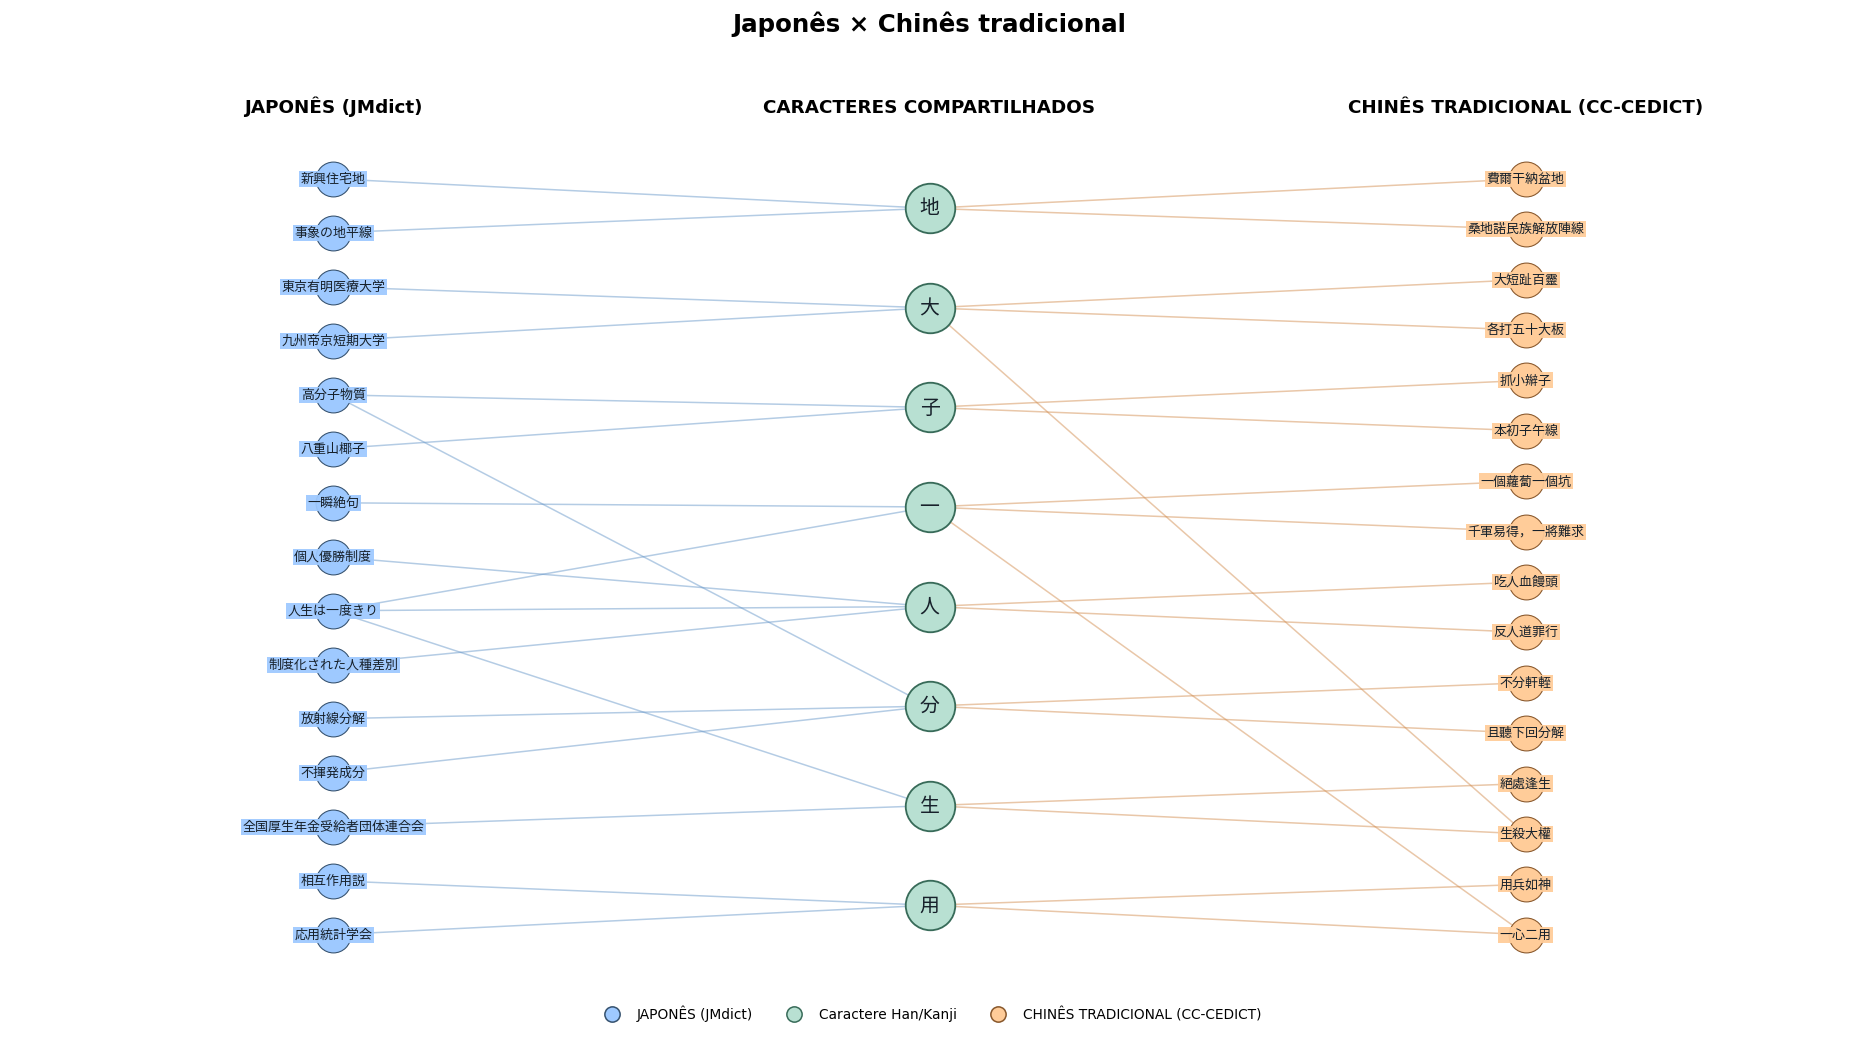

Japonês × Chinês tradicional: 8 caracteres compartilhados; 15 palavras à esquerda; 16 palavras à direita; 36 ligações na amostra visual.


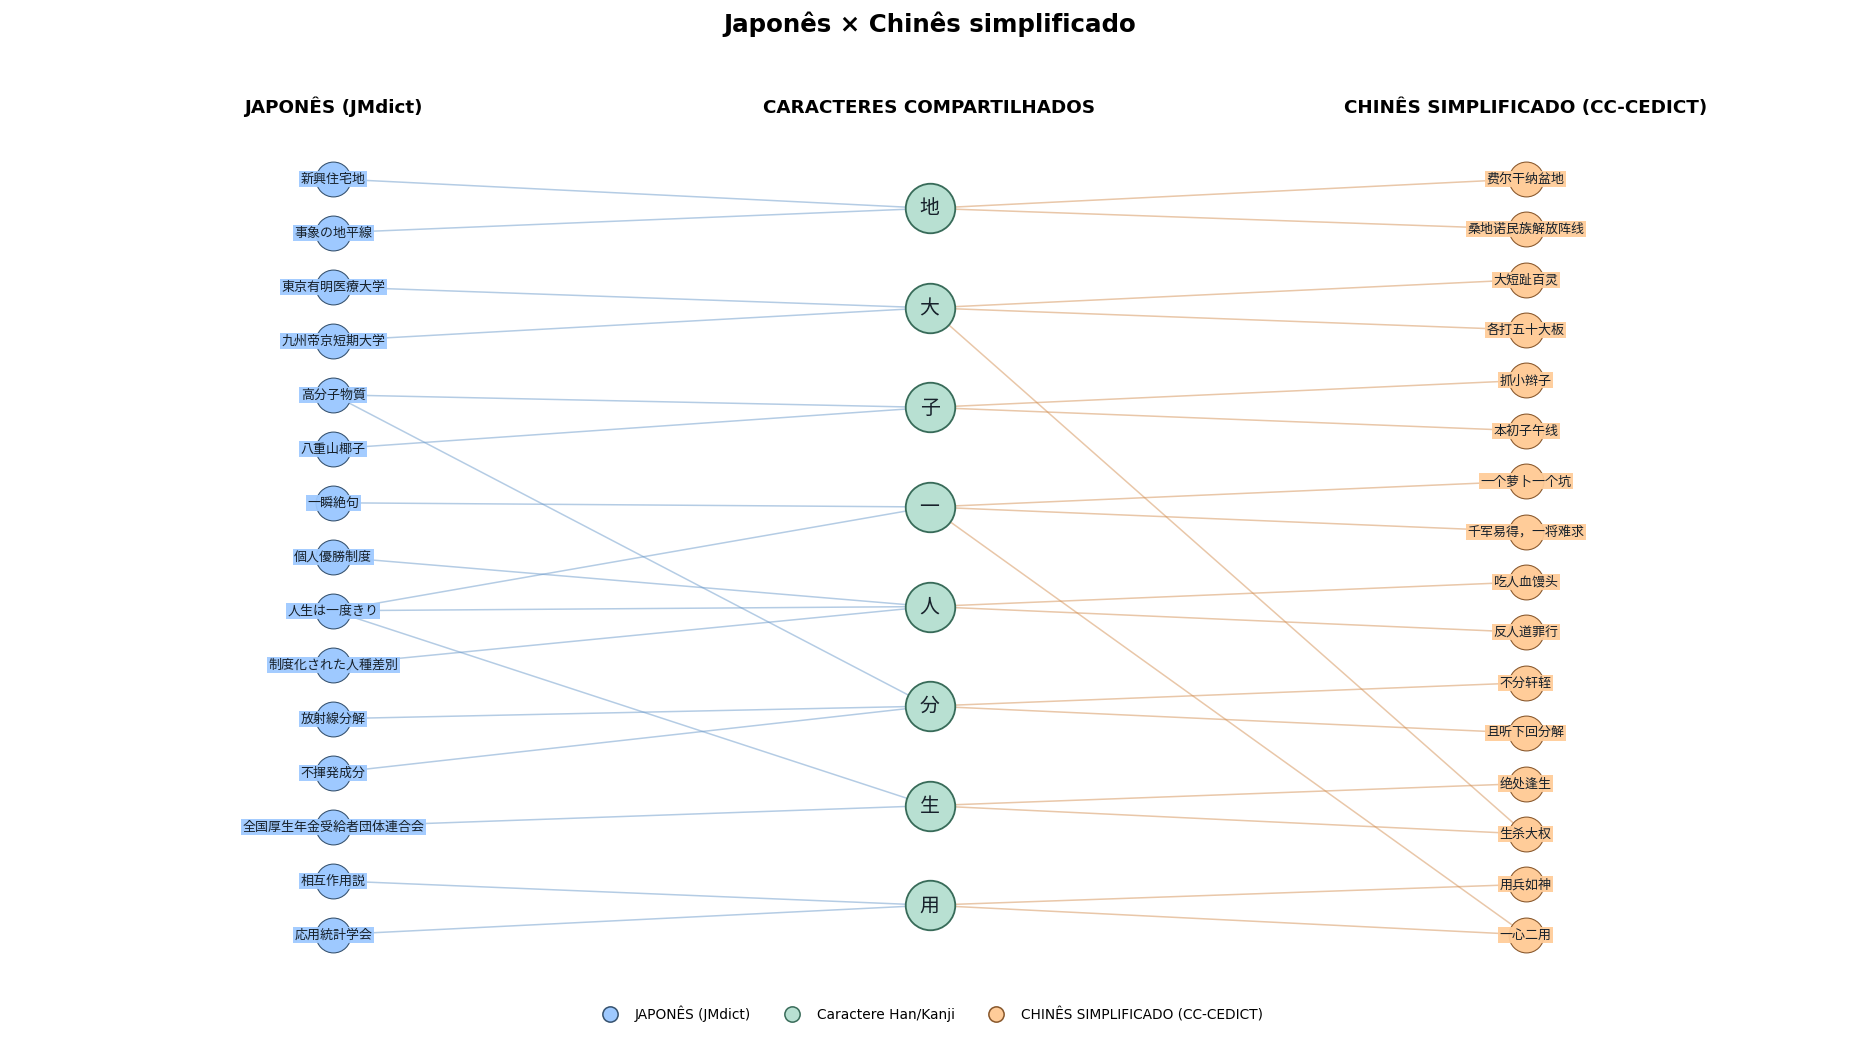

Japonês × Chinês simplificado: 8 caracteres compartilhados; 15 palavras à esquerda; 16 palavras à direita; 36 ligações na amostra visual.


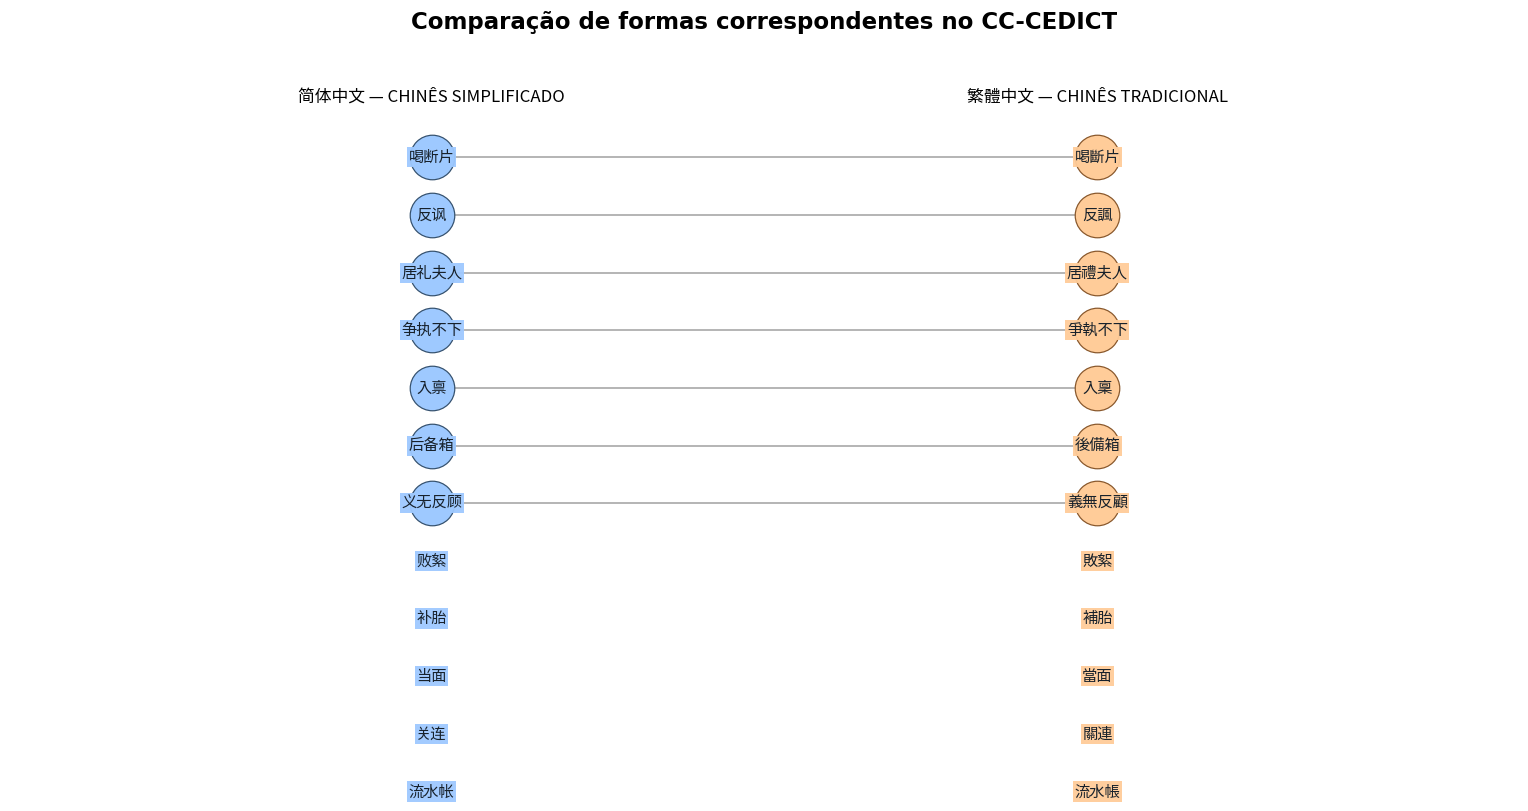

Chinês simplificado × tradicional: 12 pares distintos exibidos (cada linha conecta duas formas da mesma entrada do CC-CEDICT).


In [12]:
# Contagens antes dos desenhos: ajudam a distinguir volume de dados e limite visual.
def _chars_with_prefix(graph, prefixes):
    prefixes = tuple(prefixes)
    return {
        char_node
        for char_node, data in graph.nodes(data=True)
        if data.get("bipartite") == "character"
        and any(neighbor.startswith(prefixes) for neighbor in graph.neighbors(char_node))
    }

print("Resumo das redes completas carregadas:")
print(f"  Caracteres no japonês: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)))}")
print(f"  Caracteres no chinês tradicional: {len(_chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Caracteres no chinês simplificado: {len(_chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")
print(f"  Compartilhados japonês/tradicional: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Compartilhados japonês/simplificado: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")

plot_language_comparison(
    G_jp_vs_trad,
    "Japonês × Chinês tradicional",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS TRADICIONAL (CC-CEDICT)", ["CN_TRAD_WORD:"]
)

plot_language_comparison(
    G_jp_vs_simp,
    "Japonês × Chinês simplificado",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO (CC-CEDICT)", ["CN_WORD:"]
)

plot_simplified_traditional_pairs(df_cn_sample)

## 12. Grafos interativos (opcionais na tela)

Os HTMLs são gerados em `resultados/grafos/` e abrem no navegador. Para embutir as três redes,
ative `INTERACTIVE_INLINE` na configuração. Isso evita salvar megabytes de JavaScript nas
saídas do notebook. Arraste os nós, use o zoom e passe o mouse para consultar definições.

No terceiro grafo, as arestas roxas unem as formas simplificada/tradicional da mesma entrada.
Esse grafo tem relações entre palavras e serve **somente para visualização**: as estatísticas
e projeções foram calculadas nas redes bipartidas puras, antes dessas arestas.

In [13]:
# A correspondência entre variantes usa os nós já existentes, sem duplicar simplificadas.
G_cn_simp_vs_trad = nx.compose(G_cn_simp, G_cn_trad)
for simplified, traditional in df_cn_sample[["simplified", "traditional"]].itertuples(index=False, name=None):
    left, right = "CN_WORD:" + simplified, "CN_TRAD_WORD:" + traditional
    if left in G_cn_simp_vs_trad and right in G_cn_simp_vs_trad:
        G_cn_simp_vs_trad.add_edge(left, right, relation="traditional_simplified_entry_pair")
assert len(G_cn_simp_vs_trad) == len(G_cn_simp) + len(G_cn_trad) - len(
    set(partition(G_cn_simp, "character")) & set(partition(G_cn_trad, "character")))

In [14]:
# Grafos interativos espalhados com PyVis.
# Arrastar = reposicionar nó | roda do mouse = zoom | passar o mouse = detalhes | clicar = destacar conexões.

from pyvis.network import Network
from IPython.display import display, HTML
import html as _html
import math as _math

# Ajustes de legibilidade/desempenho. Aumente gradualmente se o navegador suportar.
INTERACTIVE_MAX_CHARS = 12
INTERACTIVE_WORDS_PER_CHAR = 3
INTERACTIVE_HEIGHT = "760px"

# Paleta estável: a mesma variante mantém a mesma cor nos três grafos.
INTERACTIVE_COLORS = {
    "japanese": "#60A5FA",             # azul
    "chinese_traditional": "#FDBA74",  # laranja
    "chinese_simplified": "#86EFAC",   # verde
    "shared": "#DDD6FE",               # lilás: caractere Han/Kanji
}
INTERACTIVE_BORDERS = {
    "japanese": "#1D4ED8",
    "chinese_traditional": "#9A3412",
    "chinese_simplified": "#166534",
    "shared": "#7C3AED",
}
INTERACTIVE_LANGUAGE_NAMES = {
    "japanese": "Japonês (JMdict)",
    "chinese_traditional": "Chinês tradicional (CC-CEDICT)",
    "chinese_simplified": "Chinês simplificado (CC-CEDICT)",
    "shared": "Caractere Han/Kanji",
}


def _interactive_label(node, data):
    """Nome que aparece junto do nó na visualização."""
    label = data.get("label")
    if label is not None and str(label).strip():
        return str(label).strip()
    for prefix in ("JP_WORD:", "CN_TRAD_WORD:", "CN_WORD:"):
        if node.startswith(prefix):
            return node[len(prefix):]
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    return str(node)


def _interactive_ranked_chars(graph, left_prefixes, right_prefixes):
    """Seleciona caracteres conectados a palavras dos dois lados da comparação."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    ranked = []
    for char_node, attrs in graph.nodes(data=True):
        if attrs.get("bipartite") != "character" or not str(char_node).startswith("CHAR:"):
            continue
        left_words = [n for n in graph.neighbors(char_node) if n.startswith(left_prefixes)]
        right_words = [n for n in graph.neighbors(char_node) if n.startswith(right_prefixes)]
        if left_words and right_words:
            ranked.append((char_node, left_words, right_words))
    ranked.sort(
        key=lambda item: (min(len(item[1]), len(item[2])), len(item[1]) + len(item[2]), item[0]),
        reverse=True,
    )
    return ranked


def _interactive_sample(graph, left_prefixes, right_prefixes,
                        max_chars=INTERACTIVE_MAX_CHARS,
                        words_per_char=INTERACTIVE_WORDS_PER_CHAR):
    """Amostra visual de hubs; não há garantia de conectividade nem representatividade."""
    ranked = _interactive_ranked_chars(graph, left_prefixes, right_prefixes)
    if not ranked:
        return graph.subgraph([]).copy(), []

    chosen_chars = ranked[:max_chars]
    chosen_nodes = set()
    for char_node, left_words, right_words in chosen_chars:
        chosen_nodes.add(char_node)
        for words, prefixes in ((left_words, tuple(left_prefixes)), (right_words, tuple(right_prefixes))):
            # Prioriza palavras com mais ligações a caracteres, para revelar interseções entre palavras.
            words = sorted(
                words,
                key=lambda node: (-graph.degree(node), _interactive_label(node, graph.nodes[node]))
            )[:words_per_char]
            chosen_nodes.update(words)

    # Na comparação simplificado/tradicional, inclui a forma correspondente ligada pela mesma entrada.
    # Isso deixa explícito quando dois nós são variantes da mesma entrada do dicionário.
    for node in list(chosen_nodes):
        if node not in graph:
            continue
        for neighbor in graph.neighbors(node):
            relation = graph.edges[node, neighbor].get("relation", "")
            if relation == "traditional_simplified_entry_pair":
                chosen_nodes.add(neighbor)

    sample = graph.subgraph(chosen_nodes).copy()
    return sample, chosen_chars


def _interactive_detail_maps(sample):
    details = {"japanese": {}, "chinese_simplified": {}, "chinese_traditional": {}}
    for node, attrs in sample.nodes(data=True):
        language = attrs.get("language")
        if language not in details:
            continue
        text = f"Leitura: {attrs.get('reading', '')}. Definição: {attrs.get('definition', '')}"
        details[language][attrs["label"]] = [text]
    return details


def _interactive_node_title(node, attrs, full_graph, left_prefixes, right_prefixes, detail_maps):
    label = _interactive_label(node, attrs)
    language = attrs.get("language", "shared")
    language_name = INTERACTIVE_LANGUAGE_NAMES.get(language, str(language))
    chunks = [f"<b>{_html.escape(language_name)}</b>", f"Forma: {_html.escape(label)}"]

    if attrs.get("bipartite") == "character":
        left_count = sum(n.startswith(tuple(left_prefixes)) for n in full_graph.neighbors(node))
        right_count = sum(n.startswith(tuple(right_prefixes)) for n in full_graph.neighbors(node))
        chunks.append(f"Palavras ligadas no lado esquerdo: {left_count}")
        chunks.append(f"Palavras ligadas no lado direito: {right_count}")
    else:
        detail_key = language if language in detail_maps else None
        if detail_key:
            for detail in detail_maps[detail_key].get(label, []):
                if detail:
                    chunks.append(_html.escape(detail))
        count = sum(full_graph.nodes[n].get("bipartite") == "character" for n in full_graph.neighbors(node))
        chunks.append(f"Caracteres ligados: {count}")
    return "<br>".join(chunks)


def _display_force_graph(graph, title, left_name, left_prefixes,
                         right_name, right_prefixes):
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    sample, ranked_chars = _interactive_sample(
        graph, left_prefixes, right_prefixes,
        max_chars=INTERACTIVE_MAX_CHARS,
        words_per_char=INTERACTIVE_WORDS_PER_CHAR,
    )
    if sample.number_of_nodes() == 0:
        print(f"{title}: não foram encontrados caracteres conectando os dois lados com os dados atuais.")
        return

    net = Network(
        height=INTERACTIVE_HEIGHT,
        width="100%",
        directed=False,
        notebook=True,
        cdn_resources="in_line",
        bgcolor="#FFFFFF",
        font_color="#1F2937",
    )
    detail_maps = _interactive_detail_maps(sample)

    for node, attrs in sample.nodes(data=True):
        label = _interactive_label(node, attrs)
        language = attrs.get("language", "shared")
        color = INTERACTIVE_COLORS.get(language, "#D1D5DB")
        border = INTERACTIVE_BORDERS.get(language, "#6B7280")
        is_character = attrs.get("bipartite") == "character"
        full_degree = graph.degree(node) if node in graph else sample.degree(node)
        size = (18 + min(13, int(_math.log1p(full_degree) * 2.2))) if is_character else (12 + min(5, sample.degree(node)))
        font_size = 18 if is_character else 12
        net.add_node(
            str(node),
            label=label,
            title=_interactive_node_title(
                node, attrs, graph, left_prefixes, right_prefixes, detail_maps
            ),
            color={"background": color, "border": border, "highlight": {"background": "#FDE68A", "border": "#111827"}},
            borderWidth=1.6,
            size=size,
            shape="diamond" if is_character else "dot",
            font={"size": font_size, "face": "Arial, sans-serif", "strokeWidth": 2, "strokeColor": "#FFFFFF"},
            margin=7,
            shadow={"enabled": True, "size": 4, "x": 1, "y": 1},
        )

    for u, v, edge_attrs in sample.edges(data=True):
        relation = edge_attrs.get("relation", "contains_character")
        if relation == "traditional_simplified_entry_pair":
            edge_color = "#9333EA"
            edge_title = "Duas formas correspondentes na mesma entrada do CC-CEDICT"
            width = 2.8
            dashes = False
        else:
            word_node = u if sample.nodes[u].get("bipartite") == "word" else v
            word_language = sample.nodes[word_node].get("language", "shared")
            edge_color = INTERACTIVE_COLORS.get(word_language, "#9CA3AF")
            char_node = v if word_node == u else u
            edge_title = f"{_html.escape(_interactive_label(word_node, sample.nodes[word_node]))} contém o caractere {_html.escape(_interactive_label(char_node, sample.nodes[char_node]))}"
            width = 1.5
            dashes = False
        net.add_edge(
            str(u), str(v), color=edge_color, title=edge_title,
            width=width, dashes=dashes,
        )

    net.set_options(r"""var options = {
      "nodes": {"scaling": {"min": 10, "max": 32}, "font": {"size": 12}, "labelHighlightBold": true},
      "edges": {"smooth": {"enabled": true, "type": "dynamic"}, "selectionWidth": 2.5, "hoverWidth": 1.5},
      "layout": {"randomSeed": 42, "improvedLayout": true},
      "interaction": {"hover": true, "tooltipDelay": 120, "navigationButtons": true,
                      "keyboard": {"enabled": true, "bindToWindow": false},
                      "dragNodes": true, "dragView": true, "zoomView": true,
                      "selectConnectedEdges": true, "hideEdgesOnDrag": false},
      "physics": {"enabled": true, "solver": "barnesHut",
                   "barnesHut": {"gravitationalConstant": -18000, "centralGravity": 0.18,
                                 "springLength": 105, "springConstant": 0.035,
                                 "damping": 0.38, "avoidOverlap": 0.8},
                   "stabilization": {"enabled": true, "iterations": 650, "updateInterval": 30}}
    }""")

    # Legenda específica deste grafo: deixa claro quais idiomas estão realmente presentes.
    def _prefix_language(prefixes):
        prefixes = tuple(prefixes)
        if any(p.startswith("JP_WORD") for p in prefixes):
            return "japanese"
        if any(p.startswith(("CN_SIMP_PAIR", "CN_WORD")) for p in prefixes):
            return "chinese_simplified"
        if any(p.startswith("CN_TRAD_WORD") for p in prefixes):
            return "chinese_traditional"
        return "shared"

    left_language = _prefix_language(left_prefixes)
    right_language = _prefix_language(right_prefixes)
    palette_html = (
        f'<span style="color:{INTERACTIVE_COLORS[left_language]};font-weight:700">● {_html.escape(left_name)}</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS["shared"]};font-weight:700">◆ Caractere Han/Kanji</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS[right_language]};font-weight:700">● {_html.escape(right_name)}</span>'
    )
    has_pair_edges = any(data.get("relation") == "traditional_simplified_entry_pair" for _, _, data in sample.edges(data=True))
    if has_pair_edges:
        palette_html += ' &nbsp; <span style="color:#9333EA;font-weight:700">━ Formas da mesma entrada do CC-CEDICT</span>'
    display(HTML(
        f'<div style="font-family:Arial,sans-serif;margin:10px 0 6px 0">'
        f'<h3 style="margin:4px 0">{_html.escape(title)}</h3>'
        f'<div style="font-size:13px;line-height:1.8">{palette_html}</div>'
        f'<div style="font-size:12px;color:#4B5563">Arraste os nós, use o zoom e passe o mouse para ver detalhes. '
        f'Amostra atual: {sample.number_of_nodes()} nós e {sample.number_of_edges()} arestas.</div></div>'
    ))

    # Iframe srcdoc isole o JavaScript de cada rede, para que as três visualizações funcionem juntas.
    html_doc = net.generate_html(notebook=True)
    escaped_doc = _html.escape(html_doc, quote=True)
    iframe = (
        f'<iframe title="{_html.escape(title, quote=True)}" '
        f'width="100%" height="{INTERACTIVE_HEIGHT}" '
        'style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" '
        'sandbox="allow-scripts" '
        f'srcdoc="{escaped_doc}"></iframe>'
    )
    folder = RESULTS_DIR / "grafos"
    folder.mkdir(exist_ok=True)
    filename = "japones_tradicional" if "japonês × chinês tradicional" in title else (
        "japones_simplificado" if "japonês × chinês simplificado" in title else "simplificado_tradicional")
    (folder / f"{filename}.html").write_text(html_doc, encoding="utf-8")
    if INTERACTIVE_INLINE:
        display(HTML(iframe))
    print(f"HTML salvo: {folder / (filename + '.html')}")
    chars_shown = sum(1 for n, data in sample.nodes(data=True) if data.get("bipartite") == "character")
    print(f"{title}: {chars_shown} nós de caracteres; {sample.number_of_nodes()} nós totais; {sample.number_of_edges()} arestas.")

In [15]:
# 1. Japonês × chinês tradicional
_display_force_graph(
    G_jp_vs_trad,
    "Grafo interativo — japonês × chinês tradicional",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
)

# 2. Japonês × chinês simplificado
_display_force_graph(
    G_jp_vs_simp,
    "Grafo interativo — japonês × chinês simplificado",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO", ["CN_WORD:"],
)

# 3. Chinês simplificado × tradicional: inclui a ligação direta entre formas da mesma entrada.
_display_force_graph(
    G_cn_simp_vs_trad,
    "Grafo interativo — chinês simplificado × chinês tradicional",
    "CHINÊS SIMPLIFICADO", ["CN_WORD:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
)

HTML salvo: resultados/grafos/japones_tradicional.html
Grafo interativo — japonês × chinês tradicional: 12 nós de caracteres; 79 nós totais; 79 arestas.


HTML salvo: resultados/grafos/japones_simplificado.html
Grafo interativo — japonês × chinês simplificado: 12 nós de caracteres; 78 nós totais; 87 arestas.


HTML salvo: resultados/grafos/simplificado_tradicional.html
Grafo interativo — chinês simplificado × chinês tradicional: 12 nós de caracteres; 76 nós totais; 114 arestas.


## 13. Resposta à pergunta e limitações

A próxima célula resume a amostra efetivamente executada. Jaccard alto indica sobreposição
de **contextos de caracteres**, Jaccard baixo indica contextos diferentes ou cobertura
insuficiente. Grau relativo indica participação no vocabulário amostrado, não frequência.
Use os exemplos e tabelas para explicar os achados; não transforme o ranking em uma lista
automática de diferenças de significado.

Limitações específicas:

1. Dicionários têm coberturas e políticas editoriais diferentes; amostrar o mesmo número de
   unidades não equaliza gêneros, familiaridade ou frequência das palavras.
2. Uma amostra de mil unidades perde vizinhos e pode produzir muitos zeros de Jaccard.
   Repita com mais dados/outras sementes para avaliar estabilidade antes de generalizar.
3. Grafias japonesas variantes entram como palavras distintas; homógrafos se fundem por
   escrita. Restrições por sentido/leitura e polissemia não são completamente resolvidas.
4. Coincidência Unicode não equivale a equivalência linguística. As duas variantes chinesas
   podem compartilhar universos diferentes com o japonês.
5. A projeção perde a palavra que originou cada conexão e cria cliques dentro de palavras
   longas. Não demonstra semelhança de significado, causalidade ou desempenho pedagógico.

Próximos passos dentro do escopo: testar estabilidade da amostragem, selecionar alguns
caracteres com suporte maior e comentar suas palavras/definições manualmente. Não é
necessário adicionar embeddings, tradução automática ou um classificador.

In [16]:
conclusions = []
for variant, table in COMPARISONS.items():
    valid = table.dropna(subset=["jaccard"])
    eligible = valid[(valid["grau_cn"] >= MIN_SUPPORT) & (valid["grau_jp"] >= MIN_SUPPORT)]
    row = {"comparacao": variant + " × japones", "compartilhados": len(table),
           "jaccard_definido": len(valid), "jaccard_medio": valid["jaccard"].mean(),
           "jaccard_mediano": valid["jaccard"].median(),
           "jaccard_zero": int(valid["jaccard"].eq(0).sum()),
           "suporte_minimo": MIN_SUPPORT, "com_suporte_minimo": len(eligible)}
    conclusions.append(row)
df_conclusions = pd.DataFrame(conclusions)
display(df_conclusions.round(4))
df_conclusions.to_csv(RESULTS_DIR / "conclusoes.csv", index=False)

run_info = {"N_CN": N_CN, "N_JP": N_JP, "seed": SEED, "min_support": MIN_SUPPORT,
            "font_cjk": bool(font_candidates), "fontes": manifest,
            "versoes": {"python": sys.version.split()[0], "networkx": nx.__version__,
                        "pandas": pd.__version__, "matplotlib": __import__("matplotlib").__version__,
                        "requests": requests.__version__}}
(RESULTS_DIR / "execucao.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print("A amostra permite comparar contextos ortográficos; não permite confirmar divergência semântica.")
print("Tabelas, figuras e manifesto de execução salvos em:", RESULTS_DIR)

,comparacao,compartilhados,jaccard_definido,jaccard_medio,jaccard_mediano,jaccard_zero,suporte_minimo,com_suporte_minimo
0,cn_tradicional × japones,533,519,0.0194,0.0,451,3,117
1,cn_simplificado × japones,429,417,0.0192,0.0,363,3,99


A amostra permite comparar contextos ortográficos; não permite confirmar divergência semântica.
Tabelas, figuras e manifesto de execução salvos em: resultados
